## 1. Import Libraries

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import (
    ttest_ind, pearsonr, chi2_contingency, f_oneway
)

import statsmodels.api as sm

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    cross_val_score, GridSearchCV
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

## 2. Load Dataset

In [2]:
FILE_PATH = "Raw Data Supermaket Sales.xlsx"

OUTPUT_DIR = "week6_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")

df = pd.read_excel(FILE_PATH)

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nDescriptive Statistics:")
print(df.describe(include="all"))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (1000, 20)

First 5 Rows:
    Invoice ID Branch       City Customer type  Gender  \
0  750-67-8428      A     Yangon        Member  Female   
1  226-31-3081      C  Naypyitaw        Normal  Female   
2  631-41-3108      A     Yangon        Normal    Male   
3  123-19-1176      A     Yangon        Member    Male   
4  373-73-7910      A     Yangon        Normal    Male   

             Product line  Unit price  Quantity   Tax 5%     Total  Month  \
0       Health and beauty       74.69         7  26.1415  548.9715      1   
1  Electronic accessories       15.28         5   3.8200   80.2200      3   
2      Home and lifestyle       46.33         7  16.2155  340.5255      3   
3       Health and beauty       58.22         8  23.2880  489.0480      1   
4       Sports and travel       86.31         7  30.2085  634.3785      2   

   Day  Year       Date      Time      Payment    cogs  \
0    5  2019 2019-01-05  13:08:00      Ewallet  522.83   
1    8  2019 2019-03-08  10:29:

## 3. Data Cleaning and Preprocessing

In [3]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text values
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].astype("string").str.strip()

# Convert Date column
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Check duplicate invoice IDs
print("Duplicate Invoice IDs:",
      df["Invoice ID"].duplicated().sum())

# Convert numeric columns
numeric_columns = [
    "Unit price", "Quantity", "Total",
    "Rating", "gross income"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Validate numeric values
print("Invalid Unit Prices:",
      (df["Unit price"] <= 0).sum())

print("Invalid Quantities:",
      (df["Quantity"] <= 0).sum())

print("Invalid Ratings:",
      ((df["Rating"] < 1) | (df["Rating"] > 10)).sum())

Duplicate Invoice IDs: 0
Invalid Unit Prices: 0
Invalid Quantities: 0
Invalid Ratings: 0


## 4. Feature Engineering

In [4]:
# Extract month name
df["Month_Name"] = df["Date"].dt.month_name()

# Extract day of week
df["Day_of_Week"] = df["Date"].dt.day_name()

# Extract month number
df["Month_Number"] = df["Date"].dt.month

print(df[[
    "Date", "Month_Name",
    "Day_of_Week", "Month_Number"
]].head())

        Date Month_Name Day_of_Week  Month_Number
0 2019-01-05    January    Saturday             1
1 2019-03-08      March      Friday             3
2 2019-03-03      March      Sunday             3
3 2019-01-27    January      Sunday             1
4 2019-02-08   February      Friday             2


## 5. Exploratory Data Analysis (EDA)

In [5]:
print("Total Sales:", df["Total"].sum())

print("Total Quantity:", df["Quantity"].sum())

print("Gross Income:", df["gross income"].sum())

print("Average Transaction:", df["Total"].mean())

print("Median Transaction:", df["Total"].median())

print("Average Rating:", df["Rating"].mean())


# Sales by Branch
print("\nSales by Branch:")
print(df.groupby("Branch")["Total"].sum())


# Sales by Product Line
print("\nSales by Product Line:")
print(df.groupby("Product line")["Total"].sum())


# Sales by Customer Type
print("\nSales by Customer Type:")
print(df.groupby("Customer type")["Total"].sum())


# Sales by Payment Method
print("\nSales by Payment Method:")
print(df.groupby("Payment")["Total"].sum())


# Monthly Sales
print("\nMonthly Sales:")
print(df.groupby("Month_Number")["Total"].sum())

Total Sales: 322966.749
Total Quantity: 5510
Gross Income: 15379.368999999999
Average Transaction: 322.966749
Median Transaction: 253.848
Average Rating: 6.9727

Sales by Branch:
Branch
A    106200.3705
B    106197.6720
C    110568.7065
Name: Total, dtype: float64

Sales by Product Line:
Product line
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Food and beverages        56144.8440
Health and beauty         49193.7390
Home and lifestyle        53861.9130
Sports and travel         55122.8265
Name: Total, dtype: float64

Sales by Customer Type:
Customer type
Member    164223.444
Normal    158743.305
Name: Total, dtype: float64

Sales by Payment Method:
Payment
Cash           112206.570
Credit card    100767.072
Ewallet        109993.107
Name: Total, dtype: float64

Monthly Sales:
Month_Number
1    116291.868
2     97219.374
3    109455.507
Name: Total, dtype: float64


## 6. Outlier Detection Using IQR

In [6]:
Q1 = df["Total"].quantile(0.25)

Q3 = df["Total"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Total"] < lower_limit) |
    (df["Total"] > upper_limit)
]

print("Q1:", Q1)

print("Q3:", Q3)

print("IQR:", IQR)

print("Lower Limit:", lower_limit)

print("Upper Limit:", upper_limit)

print("Number of Outliers:", len(outliers))

Q1: 124.422375
Q3: 471.35024999999996
IQR: 346.927875
Lower Limit: -395.9694375
Upper Limit: 991.7420625
Number of Outliers: 9


## 7. Data Visualization

In [7]:
def save_plot(filename):

    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

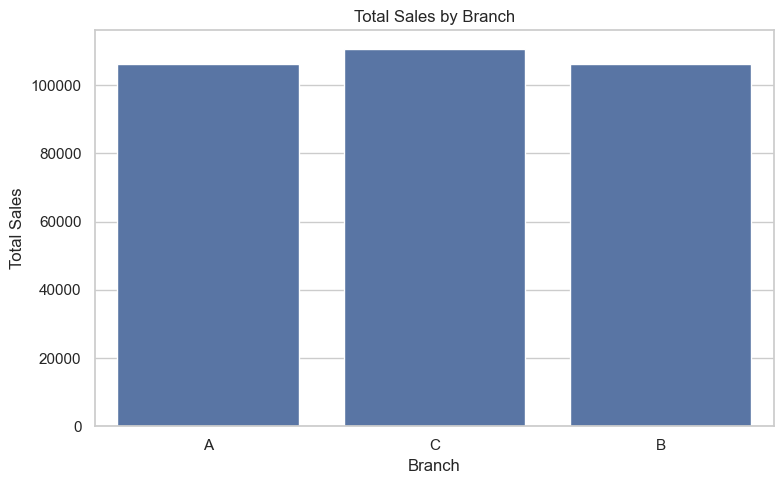

In [8]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Branch",
    y="Total",
    estimator=sum,
    errorbar=None
)

plt.title("Total Sales by Branch")

plt.ylabel("Total Sales")

save_plot("sales_by_branch.png")

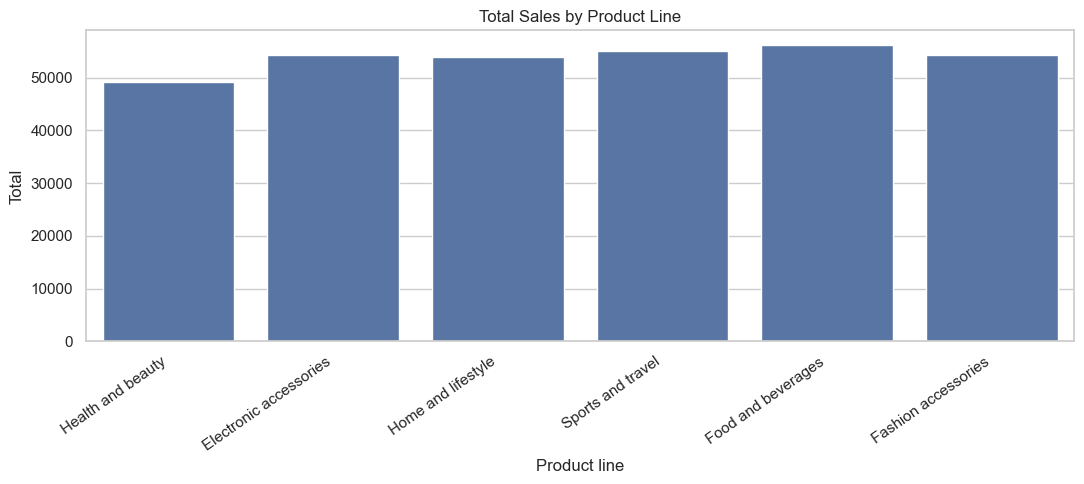

In [9]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=df,
    x="Product line",
    y="Total",
    estimator=sum,
    errorbar=None
)

plt.xticks(rotation=35, ha="right")

plt.title("Total Sales by Product Line")

save_plot("sales_by_product_line.png")

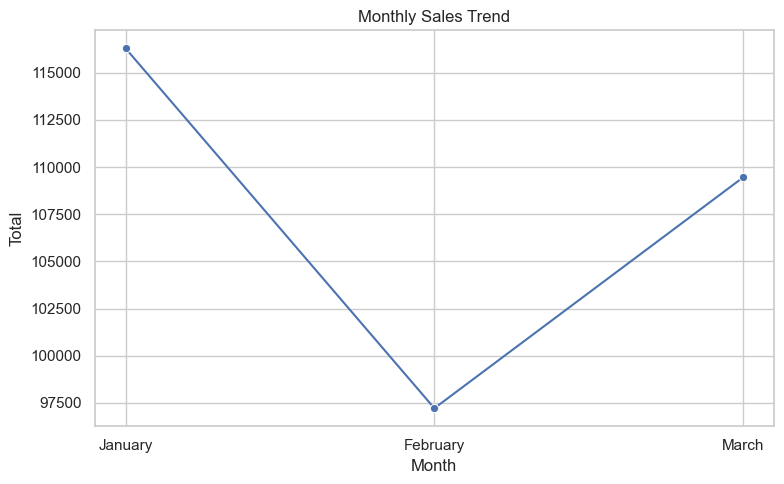

In [10]:
monthly = df.groupby(
    "Month_Number",
    as_index=False
)["Total"].sum()

month_labels = {
    1: "January",
    2: "February",
    3: "March"
}

monthly["Month"] = monthly["Month_Number"].map(month_labels)

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=monthly,
    x="Month",
    y="Total",
    marker="o"
)

plt.title("Monthly Sales Trend")

save_plot("monthly_sales.png")

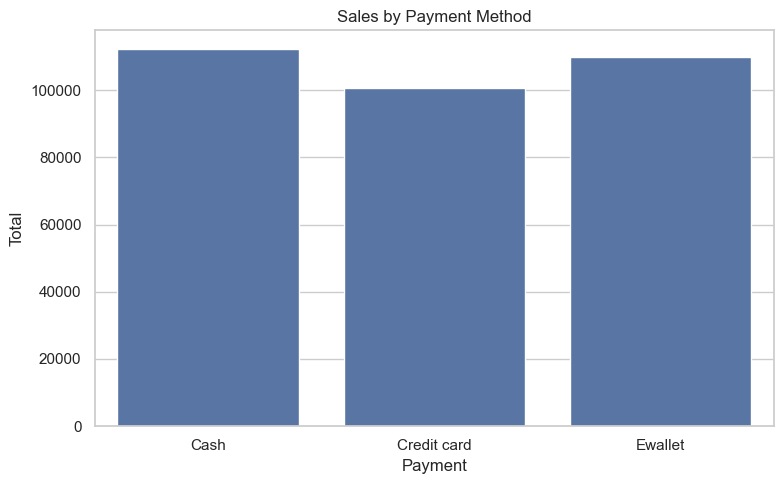

In [11]:
payment = df.groupby(
    "Payment",
    as_index=False
)["Total"].sum()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=payment,
    x="Payment",
    y="Total",
    errorbar=None
)

plt.title("Sales by Payment Method")

save_plot("sales_by_payment.png")

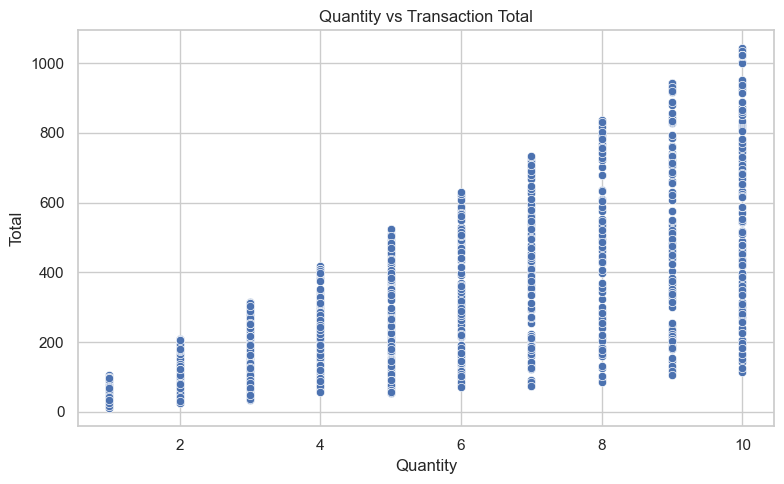

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Total"
)

plt.title("Quantity vs Transaction Total")

save_plot("quantity_vs_total.png")

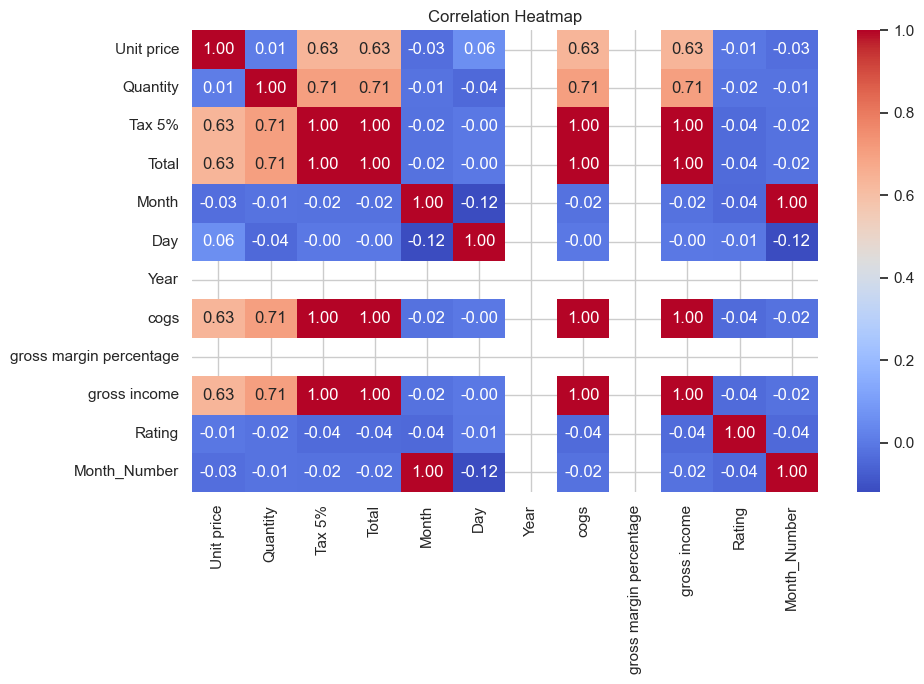

In [13]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

save_plot("correlation_heatmap.png")

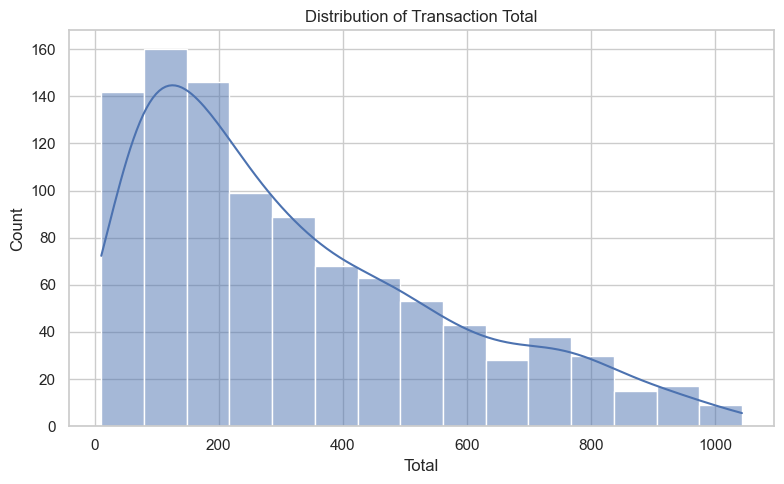

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Total"],
    kde=True
)

plt.title("Distribution of Transaction Total")

save_plot("transaction_distribution.png")

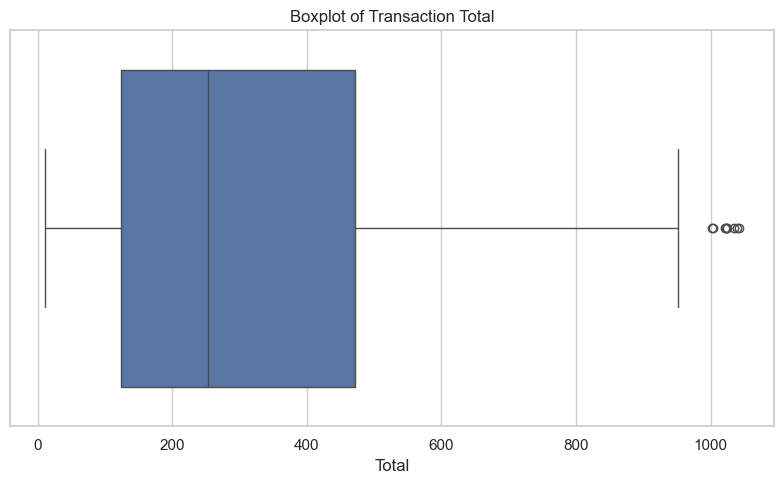

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x=df["Total"]
)

plt.title("Boxplot of Transaction Total")

save_plot("transaction_boxplot.png")

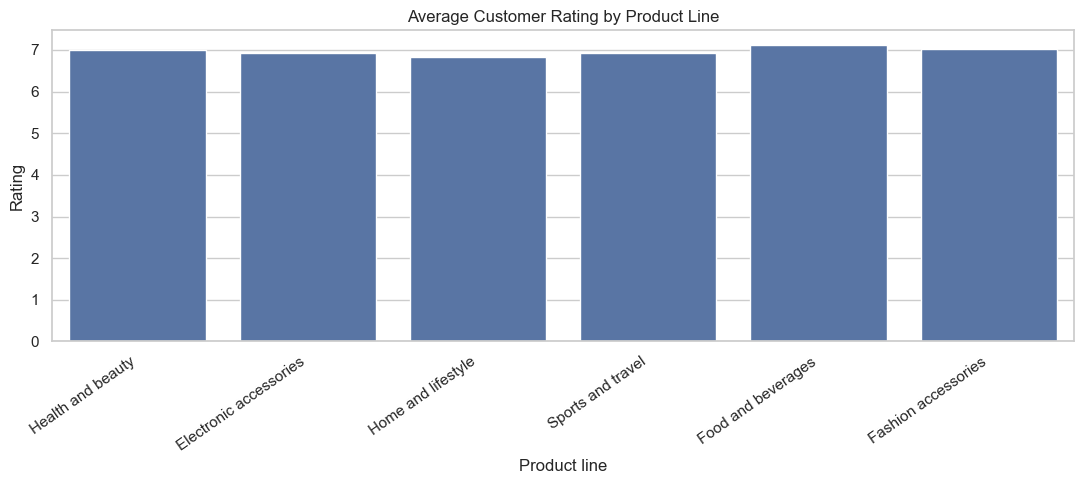

In [16]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=df,
    x="Product line",
    y="Rating",
    errorbar=None
)

plt.xticks(rotation=35, ha="right")

plt.title("Average Customer Rating by Product Line")

save_plot("rating_by_product_line.png")

## 8. Statistical Analysis and Hypothesis Testing

In [17]:
member = df.loc[
    df["Customer type"] == "Member",
    "Total"
].dropna()

normal = df.loc[
    df["Customer type"] == "Normal",
    "Total"
].dropna()

t_stat, p_value = ttest_ind(
    member,
    normal,
    equal_var=False
)

print("T-statistic:", t_stat)

print("P-value:", p_value)

T-statistic: 0.6215475684596813
P-value: 0.5343813752186699


In [18]:
valid_data = df[["Quantity", "Total"]].dropna()

r, p_value = pearsonr(
    valid_data["Quantity"],
    valid_data["Total"]
)

print("Correlation Coefficient:", r)

print("P-value:", p_value)

Correlation Coefficient: 0.7055101859433062
P-value: 2.063947519679584e-151


In [19]:
contingency = pd.crosstab(
    df["Gender"],
    df["Product line"]
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency
)

print("Chi-Square Value:", chi2)

print("P-value:", p_value)

print("Degrees of Freedom:", dof)

Chi-Square Value: 5.7444558595826445
P-value: 0.33188385805539106
Degrees of Freedom: 5


In [20]:
rating_groups = [
    group["Rating"].dropna().values
    for _, group in df.groupby("Product line")
]

f_stat, p_value = f_oneway(*rating_groups)

print("F-statistic:", f_stat)

print("P-value:", p_value)

F-statistic: 0.5398947419806559
P-value: 0.7461368538761987


In [21]:
branch_groups = [
    group["Total"].dropna().values
    for _, group in df.groupby("Branch")
]

f_stat, p_value = f_oneway(*branch_groups)

print("F-statistic:", f_stat)

print("P-value:", p_value)

F-statistic: 0.8845828327760512
P-value: 0.413210174367147


In [22]:
month_groups = [
    group["Total"].dropna().values
    for _, group in df.groupby("Month_Number")
]

f_stat, p_value = f_oneway(*month_groups)

print("F-statistic:", f_stat)

print("P-value:", p_value)

F-statistic: 0.26336478725985
P-value: 0.7685149658919843


In [23]:
regression_data = df[
    ["Unit price", "gross income"]
].dropna()

X_reg = sm.add_constant(
    regression_data["Unit price"]
)

y_reg = regression_data["gross income"]

model = sm.OLS(
    y_reg,
    X_reg
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           gross income   R-squared:                       0.402
Model:                            OLS   Adj. R-squared:                  0.401
Method:                 Least Squares   F-statistic:                     670.6
Date:                Sun, 01 Nov 2026   Prob (F-statistic):          1.61e-113
Time:                        21:05:09   Log-Likelihood:                -3621.8
No. Observations:                1000   AIC:                             7248.
Df Residuals:                     998   BIC:                             7257.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.2182      0.667     -0.327      0.7

## 9. Machine Learning – Product Line Classification

In [24]:
target = "Product line"

features = [
    "Branch",
    "Customer type",
    "Gender",
    "Unit price",
    "Quantity",
    "Payment",
    "Rating",
    "Day_of_Week"
]

model_df = df[
    features + [target]
].dropna().copy()

X = model_df[features]

y = model_df[target]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
  Branch Customer type  Gender  Unit price  Quantity      Payment  Rating  \
0      A        Member  Female       74.69         7      Ewallet     9.1   
1      C        Normal  Female       15.28         5         Cash     9.6   
2      A        Normal    Male       46.33         7  Credit card     7.4   
3      A        Member    Male       58.22         8      Ewallet     8.4   
4      A        Normal    Male       86.31         7      Ewallet     5.3   

  Day_of_Week  
0    Saturday  
1      Friday  
2      Sunday  
3      Sunday  
4      Friday  

Target:
0         Health and beauty
1    Electronic accessories
2        Home and lifestyle
3         Health and beauty
4         Sports and travel
Name: Product line, dtype: string


In [25]:
categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical Features:", categorical_features)

print("Numerical Features:", numeric_features)

Categorical Features: ['Branch', 'Customer type', 'Gender', 'Payment', 'Day_of_Week']
Numerical Features: ['Unit price', 'Quantity', 'Rating']


In [26]:
preprocessor = ColumnTransformer(

    transformers=[

        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),

        (
            "numerical",
            StandardScaler(),
            numeric_features
        )

    ]
)

In [27]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (800, 8)
Testing Data: (200, 8)


In [28]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## 10. Logistic Regression

In [33]:
log_model = Pipeline([

    ("preprocessor", preprocessor),

    (
        "classifier",
        LogisticRegression(max_iter=2000)
    )

])

log_model.fit(X_train, y_train)

y_pred = log_model.predict(X_test)

print("Logistic Regression Results")

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(
          y_test,
          y_pred,
          average="weighted",
          zero_division=0
      ))

print("Recall:",
      recall_score(
          y_test,
          y_pred,
          average="weighted",
          zero_division=0
      ))

print("F1 Score:",
      f1_score(
          y_test,
          y_pred,
          average="weighted",
          zero_division=0
      ))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

cv_scores = cross_val_score(
    log_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Cross Validation Mean:", cv_scores.mean())

Logistic Regression Results
Accuracy: 0.18
Precision: 0.1773641419135693
Recall: 0.18
F1 Score: 0.1758638397002822

Classification Report:
                        precision    recall  f1-score   support

Electronic accessories       0.27      0.35      0.31        34
   Fashion accessories       0.15      0.19      0.17        36
    Food and beverages       0.18      0.17      0.18        35
     Health and beauty       0.07      0.07      0.07        30
    Home and lifestyle       0.21      0.16      0.18        32
     Sports and travel       0.17      0.12      0.14        33

              accuracy                           0.18       200
             macro avg       0.18      0.18      0.17       200
          weighted avg       0.18      0.18      0.18       200

Cross Validation Mean: 0.18250000000000002


## 11. Random Forest

In [30]:
rf_model = Pipeline([

    ("preprocessor", preprocessor),

    (
        "classifier",
        RandomForestClassifier(random_state=42)
    )

])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Results")

print("Accuracy:",
      accuracy_score(y_test, rf_pred))

print("Precision:",
      precision_score(
          y_test,
          rf_pred,
          average="weighted",
          zero_division=0
      ))

print("Recall:",
      recall_score(
          y_test,
          rf_pred,
          average="weighted",
          zero_division=0
      ))

print("F1 Score:",
      f1_score(
          y_test,
          rf_pred,
          average="weighted",
          zero_division=0
      ))

print("\nClassification Report:")

print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))

cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Cross Validation Mean:", cv_scores.mean())

Random Forest Results
Accuracy: 0.135
Precision: 0.13249082335289233
Recall: 0.135
F1 Score: 0.1334631791350959

Classification Report:
                        precision    recall  f1-score   support

Electronic accessories       0.12      0.12      0.12        34
   Fashion accessories       0.08      0.08      0.08        36
    Food and beverages       0.15      0.17      0.16        35
     Health and beauty       0.10      0.10      0.10        30
    Home and lifestyle       0.11      0.09      0.10        32
     Sports and travel       0.22      0.24      0.23        33

              accuracy                           0.14       200
             macro avg       0.13      0.13      0.13       200
          weighted avg       0.13      0.14      0.13       200

Cross Validation Mean: 0.16875


## 12. Hyperparameter Tuning Using GridSearchCV

In [31]:
rf_pipe = Pipeline([

    ("preprocessor", preprocessor),

    (
        "classifier",
        RandomForestClassifier(random_state=42)
    )

])

param_grid = {

    "classifier__n_estimators": [100, 200],

    "classifier__max_depth": [None, 10, 20],

    "classifier__min_samples_split": [2, 5],

    "classifier__min_samples_leaf": [1, 2]

}

grid = GridSearchCV(

    rf_pipe,

    param_grid,

    cv=cv,

    scoring="accuracy",

    n_jobs=-1,

    verbose=1

)

grid.fit(X_train, y_train)

tuned_predictions = grid.predict(X_test)

print("Best Parameters:")
print(grid.best_params_)

print("Best CV Accuracy:")
print(grid.best_score_)

print("Test Accuracy:")
print(accuracy_score(y_test, tuned_predictions))

print("Weighted Precision:")
print(precision_score(
    y_test,
    tuned_predictions,
    average="weighted",
    zero_division=0
))

print("Weighted Recall:")
print(recall_score(
    y_test,
    tuned_predictions,
    average="weighted",
    zero_division=0
))

print("Weighted F1 Score:")
print(f1_score(
    y_test,
    tuned_predictions,
    average="weighted",
    zero_division=0
))

print("\nClassification Report:")

print(classification_report(
    y_test,
    tuned_predictions,
    zero_division=0
))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}
Best CV Accuracy:
0.17
Test Accuracy:
0.175
Weighted Precision:
0.164211158526948
Weighted Recall:
0.175
Weighted F1 Score:
0.16846553598608394

Classification Report:
                        precision    recall  f1-score   support

Electronic accessories       0.22      0.24      0.23        34
   Fashion accessories       0.18      0.22      0.20        36
    Food and beverages       0.16      0.17      0.16        35
     Health and beauty       0.00      0.00      0.00        30
    Home and lifestyle       0.17      0.12      0.14        32
     Sports and travel       0.24      0.27      0.26        33

              accuracy                           0.17       200
             macro avg       0.16      0.17      0.17       200
          weighted avg       0.16      0.